In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Load the UCI Wine Quality dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

# Display first five records
display(df.head())

# Display dataset dimensions
print("Dataset Shape:", df.shape)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Dataset Shape: (1599, 12)


In [ ]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Count duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate Records: 240


In [ ]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Fill missing numerical values using median
df = df.fillna(df.median(numeric_only=True))

# Display updated information
print("Shape after cleaning:", df.shape)

print("Remaining Duplicate Records:", df.duplicated().sum())

Shape after cleaning: (1359, 12)
Remaining Duplicate Records: 0


In [ ]:
# Select numerical input features (exclude quality)
numeric_cols = df.drop(columns=["quality"]).select_dtypes(
    include=np.number
).columns

# Apply IQR method
for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Clip outliers
    df[col] = df[col].clip(lower, upper)

# Display processed records
display(df.head())

print("Outlier treatment completed successfully")

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


Outlier treatment completed successfully


In [ ]:
# Separate input features and target column
features = df.drop(columns=["quality"])

# Create Min-Max scaler
scaler = MinMaxScaler()

# Normalise input features
scaled = scaler.fit_transform(features)

# Convert into DataFrame
df_scaled = pd.DataFrame(
    scaled,
    columns=features.columns
)

# Add original target column
df_scaled["quality"] = df["quality"].values

# Display normalised dataset
display(df_scaled.head())

# Check normalised feature range
print("\nMinimum Feature Value:", df_scaled.drop(columns=["quality"]).min().min())

print("Maximum Feature Value:", df_scaled.drop(columns=["quality"]).max().max())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0.361290,0.648045,0.000000,0.363636,0.446429,0.243902,0.236287,0.622748,0.769737,0.343284,0.196078,5
1,0.412903,0.849162,0.000000,0.618182,0.708333,0.585366,0.514768,0.510135,0.361842,0.522388,0.274510,5
2,0.412903,0.715084,0.042553,0.509091,0.636905,0.341463,0.405063,0.532658,0.440789,0.477612,0.274510,5
3,0.851613,0.178771,0.595745,0.363636,0.434524,0.390244,0.455696,0.645270,0.309211,0.373134,0.274510,6
4,0.361290,0.603352,0.000000,0.327273,0.434524,0.292683,0.286920,0.622748,0.769737,0.343284,0.196078,5



Minimum Feature Value: 0.0
Maximum Feature Value: 1.0000000000000004


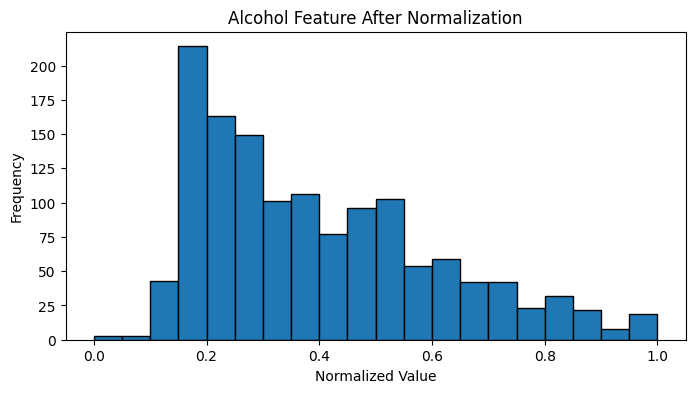


Final Dataset Shape: (1359, 12)
Processed dataset saved successfully


In [ ]:
# Plot histogram of normalised alcohol feature
plt.figure(figsize=(8, 4))

plt.hist(
    df_scaled["alcohol"],
    bins=20,
    edgecolor="black"
)

plt.title("Alcohol Feature After Normalization")
plt.xlabel("Normalized Value")
plt.ylabel("Frequency")

plt.show()

# Save processed dataset
df_scaled.to_csv("cleaned_wine_quality.csv", index=False)

print("\nFinal Dataset Shape:", df_scaled.shape)

print("Processed dataset saved successfully")

In [ ]:
from google.colab import files

files.download("cleaned_wine_quality.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>